In [28]:
import pandas as pd

# Load files
patients = pd.read_csv("patients.csv")
vitals = pd.read_csv("vitals_timeseries.csv")
labs = pd.read_csv("labs_timeseries.csv")

# Step 1: Merge vitals and labs
hourly_data = pd.merge(
    vitals,
    labs,
    on=["patient_id", "hour_from_admission"],
    how="inner"
)

# Step 2: Merge with patient information
final_dataset = pd.merge(
    hourly_data,
    patients,
    on="patient_id",
    how="left"
)

# Save merged dataset
final_dataset.to_csv("hospital_deterioration_hourly_panel.csv", index=False)

print(final_dataset.head())

   patient_id  hour_from_admission  heart_rate  respiratory_rate  spo2_pct  \
0           1                    0       68.58             14.47     96.52   
1           1                    1       67.03             13.87     94.94   
2           1                    2       69.05             14.63     94.45   
3           1                    3       69.07             14.42     95.16   
4           1                    4       73.35             15.62     95.83   

   temperature_c  systolic_bp  diastolic_bp oxygen_device  oxygen_flow  ...  \
0          37.18       108.94         78.43          none          0.0  ...   
1          37.25       111.73         79.14          none          0.0  ...   
2          37.29       111.48         78.86          none          0.0  ...   
3          37.27       110.68         76.79          none          0.0  ...   
4          37.21       110.38         75.47          none          0.0  ...   

   sepsis_risk_score  age  gender  comorbidity_index  ad

In [29]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
#Load the dataset
df = pd.read_csv("merged hospital deterioration hourly panel dataset.csv")
df

,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,...,sepsis_risk_score,age,gender,comorbidity_index,admission_type,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour
0,1,0,68.58,14.47,96.52,37.18,108.94,78.43,none,0.0,...,0.2621,24,M,2,Elective,0.2173,17,0,0,-1
1,1,1,67.03,13.87,94.94,37.25,111.73,79.14,none,0.0,...,0.3353,24,M,2,Elective,0.2173,17,0,0,-1
2,1,2,69.05,14.63,94.45,37.29,111.48,78.86,none,0.0,...,0.1678,24,M,2,Elective,0.2173,17,0,0,-1
3,1,3,69.07,14.42,95.16,37.27,110.68,76.79,none,0.0,...,0.1961,24,M,2,Elective,0.2173,17,0,0,-1
4,1,4,73.35,15.62,95.83,37.21,110.38,75.47,none,0.0,...,0.3000,24,M,2,Elective,0.2173,17,0,0,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
417861,10000,24,89.82,20.65,95.46,36.43,122.05,70.56,none,0.0,...,0.3906,62,F,1,ED,0.2059,29,0,0,-1
417862,10000,25,92.38,20.80,95.30,36.46,124.08,72.08,none,0.0,...,0.4531,62,F,1,ED,0.2059,29,0,0,-1
417863,10000,26,94.65,21.43,94.39,36.43,123.59,71.41,none,0.0,...,0.1993,62,F,1,ED,0.2059,29,0,0,-1
417864,10000,27,95.72,21.23,94.90,36.46,121.17,70.60,none,0.0,...,0.5195,62,F,1,ED,0.2059,29,0,0,-1


In [31]:
df.head()

,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,...,sepsis_risk_score,age,gender,comorbidity_index,admission_type,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour
0,1,0,68.58,14.47,96.52,37.18,108.94,78.43,none,0.0,...,0.2621,24,M,2,Elective,0.2173,17,0,0,-1
1,1,1,67.03,13.87,94.94,37.25,111.73,79.14,none,0.0,...,0.3353,24,M,2,Elective,0.2173,17,0,0,-1
2,1,2,69.05,14.63,94.45,37.29,111.48,78.86,none,0.0,...,0.1678,24,M,2,Elective,0.2173,17,0,0,-1
3,1,3,69.07,14.42,95.16,37.27,110.68,76.79,none,0.0,...,0.1961,24,M,2,Elective,0.2173,17,0,0,-1
4,1,4,73.35,15.62,95.83,37.21,110.38,75.47,none,0.0,...,0.3000,24,M,2,Elective,0.2173,17,0,0,-1


In [32]:
print(df.shape)

(417866, 27)


In [33]:
#Explore the dataset
df.columns

Index(['patient_id', 'hour_from_admission', 'heart_rate', 'respiratory_rate',
       'spo2_pct', 'temperature_c', 'systolic_bp', 'diastolic_bp',
       'oxygen_device', 'oxygen_flow', 'mobility_score', 'nurse_alert',
       'wbc_count', 'lactate', 'creatinine', 'crp_level', 'hemoglobin',
       'sepsis_risk_score', 'age', 'gender', 'comorbidity_index',
       'admission_type', 'baseline_risk_score', 'los_hours',
       'deterioration_event', 'deterioration_within_12h_from_admission',
       'deterioration_hour'],
      dtype='object')

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 417866 entries, 0 to 417865
Data columns (total 27 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   patient_id                               417866 non-null  int64  
 1   hour_from_admission                      417866 non-null  int64  
 2   heart_rate                               417866 non-null  float64
 3   respiratory_rate                         417866 non-null  float64
 4   spo2_pct                                 417866 non-null  float64
 5   temperature_c                            417866 non-null  float64
 6   systolic_bp                              417866 non-null  float64
 7   diastolic_bp                             417866 non-null  float64
 8   oxygen_device                            417866 non-null  object 
 9   oxygen_flow                              417866 non-null  float64
 10  mobility_score                  

In [35]:
df.describe()

,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_flow,mobility_score,...,crp_level,hemoglobin,sepsis_risk_score,age,comorbidity_index,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour
count,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,...,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000
mean,4978.444200,24.098240,89.258118,20.177237,93.504918,36.968563,113.398465,70.516530,7.967031,2.283012,...,34.232249,13.279612,0.493449,53.863521,4.001931,0.500319,49.196479,0.210209,0.028531,5.532783
std,2889.197834,16.935515,21.127257,6.849362,5.950330,0.451594,17.107426,10.670383,16.248186,0.925933,...,36.282849,1.160177,0.222574,20.947460,2.602512,0.210934,15.987814,0.407457,0.166483,14.523568
min,1.000000,0.000000,40.000000,8.000000,70.000000,35.240000,70.000000,40.000000,0.000000,0.000000,...,0.000000,7.000000,0.017600,18.000000,0.000000,0.031500,12.000000,0.000000,0.000000,-1.000000
25%,2454.000000,10.000000,76.920000,15.860000,92.510000,36.700000,103.980000,65.020000,0.000000,2.000000,...,15.660000,12.680000,0.325500,36.000000,2.000000,0.326700,37.000000,0.000000,0.000000,-1.000000
50%,4986.000000,21.000000,86.330000,19.330000,94.830000,36.920000,114.830000,71.470000,0.000000,2.000000,...,26.630000,13.360000,0.465850,54.000000,4.000000,0.497200,52.000000,0.000000,0.000000,-1.000000
75%,7485.000000,36.000000,96.860000,23.040000,96.850000,37.150000,124.850000,77.440000,0.700000,3.000000,...,38.670000,14.020000,0.628400,72.000000,6.000000,0.670700,63.000000,0.000000,0.000000,-1.000000
max,10000.000000,71.000000,180.000000,45.000000,100.000000,40.500000,184.560000,110.000000,56.190000,4.000000,...,250.000000,17.000000,0.999900,90.000000,8.000000,0.984700,72.000000,1.000000,1.000000,70.000000


In [36]:
df.duplicated().sum()

np.int64(0)

In [37]:
#Data cleaning
df.isnull().sum()

patient_id                                 0
hour_from_admission                        0
heart_rate                                 0
respiratory_rate                           0
spo2_pct                                   0
temperature_c                              0
systolic_bp                                0
diastolic_bp                               0
oxygen_device                              0
oxygen_flow                                0
mobility_score                             0
nurse_alert                                0
wbc_count                                  0
lactate                                    0
creatinine                                 0
crp_level                                  0
hemoglobin                                 0
sepsis_risk_score                          0
age                                        0
gender                                     0
comorbidity_index                          0
admission_type                             0
baseline_r

In [38]:
df.dtypes

patient_id                                   int64
hour_from_admission                          int64
heart_rate                                 float64
respiratory_rate                           float64
spo2_pct                                   float64
temperature_c                              float64
systolic_bp                                float64
diastolic_bp                               float64
oxygen_device                               object
oxygen_flow                                float64
mobility_score                               int64
nurse_alert                                  int64
wbc_count                                  float64
lactate                                    float64
creatinine                                 float64
crp_level                                  float64
hemoglobin                                 float64
sepsis_risk_score                          float64
age                                          int64
gender                         

In [39]:
df.select_dtypes(include='object').nunique()

oxygen_device     5
gender            2
admission_type    3
dtype: int64

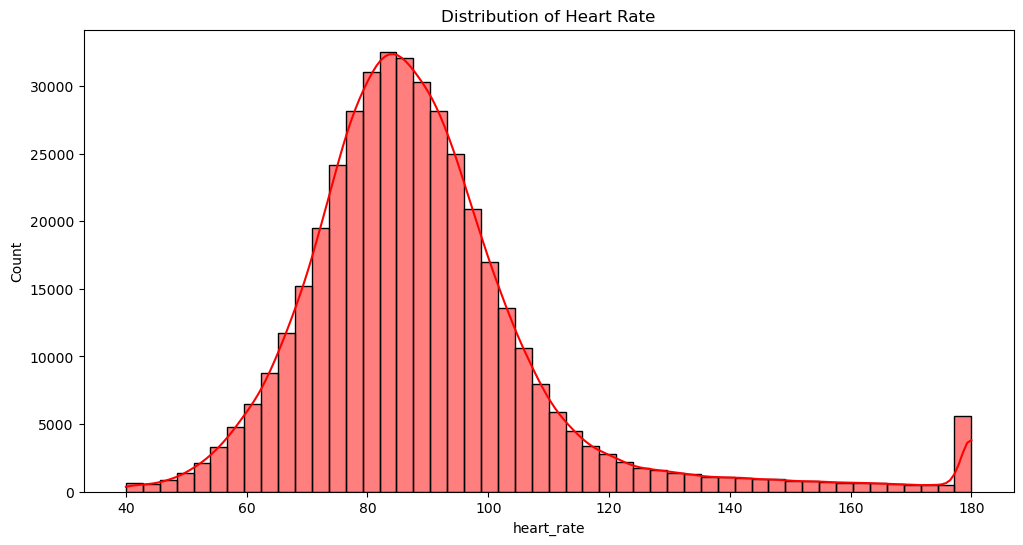

In [40]:
plt.figure(figsize=(12,6))
sns.histplot(df['heart_rate'], kde=True, bins=50, color='red')
plt.title("Distribution of Heart Rate")
plt.show()

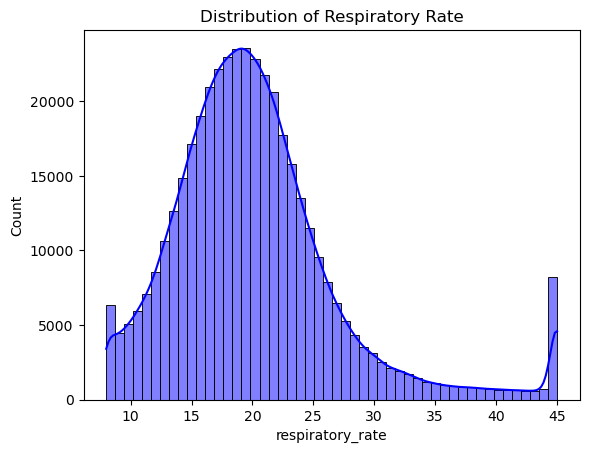

In [41]:
sns.histplot(df['respiratory_rate'], kde=True, bins=50, color='blue')
plt.title("Distribution of Respiratory Rate")
plt.show()

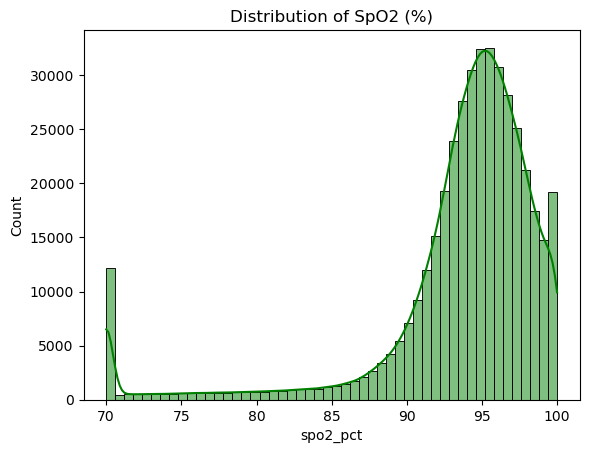

In [42]:
sns.histplot(df['spo2_pct'], kde=True, bins=50, color='green')
plt.title("Distribution of SpO2 (%)")
plt.show()

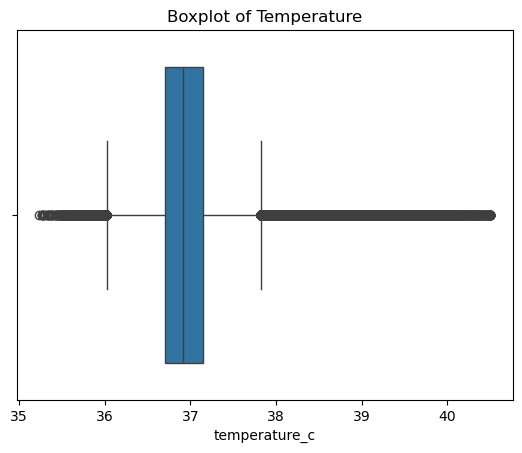

In [43]:
sns.boxplot(x=df['temperature_c'])
plt.title("Boxplot of Temperature")
plt.show()

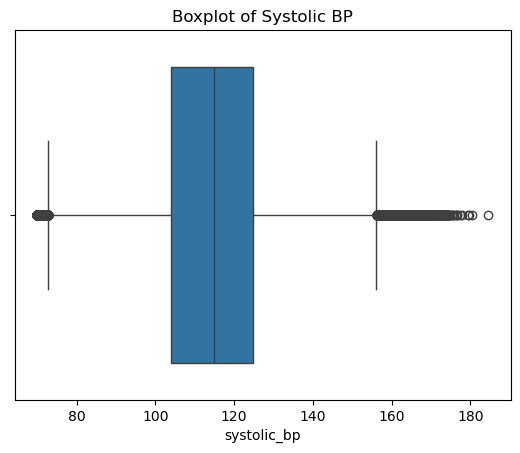

In [44]:
sns.boxplot(x=df['systolic_bp'])
plt.title("Boxplot of Systolic BP")
plt.show()

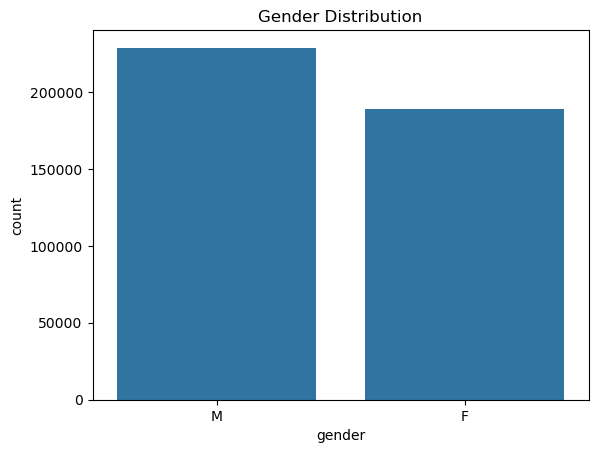

In [45]:
sns.countplot(x='gender', data=df)
plt.title("Gender Distribution")
plt.show()

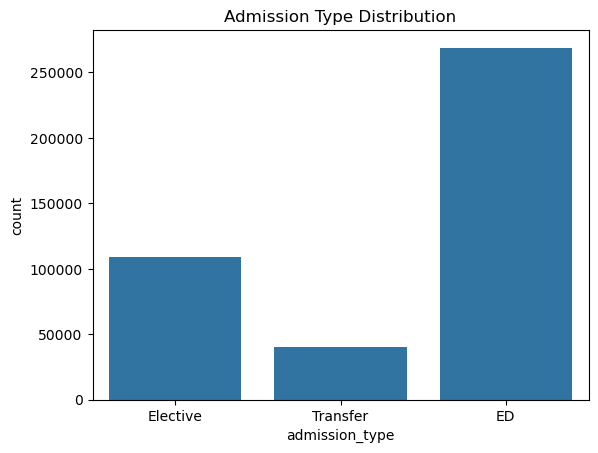

In [46]:
sns.countplot(x='admission_type', data=df)
plt.title("Admission Type Distribution")
plt.show()

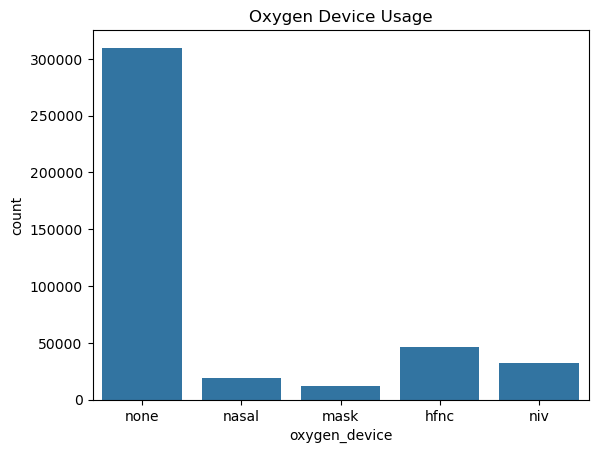

In [47]:
sns.countplot(x='oxygen_device', data=df)
plt.title("Oxygen Device Usage")
plt.show()

In [48]:
#Remove unnecessary variables
df = df.drop(columns=[
    'patient_id',
    'los_hours',
    'deterioration_event',
    'deterioration_hour'
])

In [49]:
df             #deterioration_within_12h_from_admission (target variable)

,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,mobility_score,...,creatinine,crp_level,hemoglobin,sepsis_risk_score,age,gender,comorbidity_index,admission_type,baseline_risk_score,deterioration_within_12h_from_admission
0,0,68.58,14.47,96.52,37.18,108.94,78.43,none,0.0,2,...,1.27,10.66,13.55,0.2621,24,M,2,Elective,0.2173,0
1,1,67.03,13.87,94.94,37.25,111.73,79.14,none,0.0,3,...,1.22,11.94,13.65,0.3353,24,M,2,Elective,0.2173,0
2,2,69.05,14.63,94.45,37.29,111.48,78.86,none,0.0,2,...,1.25,10.24,13.69,0.1678,24,M,2,Elective,0.2173,0
3,3,69.07,14.42,95.16,37.27,110.68,76.79,none,0.0,2,...,1.24,10.72,13.61,0.1961,24,M,2,Elective,0.2173,0
4,4,73.35,15.62,95.83,37.21,110.38,75.47,none,0.0,3,...,1.21,11.46,13.49,0.3000,24,M,2,Elective,0.2173,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
417861,24,89.82,20.65,95.46,36.43,122.05,70.56,none,0.0,4,...,1.36,14.76,13.38,0.3906,62,F,1,ED,0.2059,0
417862,25,92.38,20.80,95.30,36.46,124.08,72.08,none,0.0,1,...,1.35,14.75,13.29,0.4531,62,F,1,ED,0.2059,0
417863,26,94.65,21.43,94.39,36.43,123.59,71.41,none,0.0,1,...,1.40,12.76,13.16,0.1993,62,F,1,ED,0.2059,0
417864,27,95.72,21.23,94.90,36.46,121.17,70.60,none,0.0,3,...,1.39,14.96,13.14,0.5195,62,F,1,ED,0.2059,0


In [50]:
X = df.drop(columns=['deterioration_within_12h_from_admission'])
y = df['deterioration_within_12h_from_admission']

In [51]:
df.select_dtypes(include='object').columns             #Identifying the categorical variables 

Index(['oxygen_device', 'gender', 'admission_type'], dtype='object')

In [52]:
for col in df.select_dtypes(include='object').columns:
    print(f"\nColumn: {col}")
    print(df[col].unique())


Column: oxygen_device
['none' 'nasal' 'mask' 'hfnc' 'niv']

Column: gender
['M' 'F']

Column: admission_type
['Elective' 'Transfer' 'ED']


In [53]:
X = pd.get_dummies(
    X,
    columns=['gender', 'oxygen_device', 'admission_type'],
    drop_first=True
)

In [54]:
X.head()

,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_flow,mobility_score,nurse_alert,...,age,comorbidity_index,baseline_risk_score,gender_M,oxygen_device_mask,oxygen_device_nasal,oxygen_device_niv,oxygen_device_none,admission_type_Elective,admission_type_Transfer
0,0,68.58,14.47,96.52,37.18,108.94,78.43,0.0,2,0,...,24,2,0.2173,True,False,False,False,True,True,False
1,1,67.03,13.87,94.94,37.25,111.73,79.14,0.0,3,0,...,24,2,0.2173,True,False,False,False,True,True,False
2,2,69.05,14.63,94.45,37.29,111.48,78.86,0.0,2,0,...,24,2,0.2173,True,False,False,False,True,True,False
3,3,69.07,14.42,95.16,37.27,110.68,76.79,0.0,2,0,...,24,2,0.2173,True,False,False,False,True,True,False
4,4,73.35,15.62,95.83,37.21,110.38,75.47,0.0,3,0,...,24,2,0.2173,True,False,False,False,True,True,False


In [55]:
X.select_dtypes(include='object').columns

Index([], dtype='object')

In [56]:
from sklearn.preprocessing import StandardScaler     #Here we are doing feature scaling

scaler = StandardScaler()

In [57]:
X_scaled = scaler.fit_transform(X)

In [58]:
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

In [59]:
X_scaled.head()

,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_flow,mobility_score,nurse_alert,...,age,comorbidity_index,baseline_risk_score,gender_M,oxygen_device_mask,oxygen_device_nasal,oxygen_device_niv,oxygen_device_none,admission_type_Elective,admission_type_Transfer
0,-1.422943,-0.978742,-0.833252,0.506709,0.468202,-0.260616,0.741630,-0.490334,-0.305651,-0.533008,...,-1.425641,-0.769231,-1.341742,0.909356,-0.168856,-0.216667,-0.286874,0.59057,1.687928,-0.327181
1,-1.363895,-1.052107,-0.920851,0.241177,0.623209,-0.097529,0.808170,-0.490334,0.774342,-0.533008,...,-1.425641,-0.769231,-1.341742,0.909356,-0.168856,-0.216667,-0.286874,0.59057,1.687928,-0.327181
2,-1.304848,-0.956496,-0.809892,0.158829,0.711784,-0.112142,0.781929,-0.490334,-0.305651,-0.533008,...,-1.425641,-0.769231,-1.341742,0.909356,-0.168856,-0.216667,-0.286874,0.59057,1.687928,-0.327181
3,-1.245800,-0.955550,-0.840552,0.278150,0.667497,-0.158906,0.587934,-0.490334,-0.305651,-0.533008,...,-1.425641,-0.769231,-1.341742,0.909356,-0.168856,-0.216667,-0.286874,0.59057,1.687928,-0.327181
4,-1.186752,-0.752967,-0.665353,0.390749,0.534634,-0.176442,0.464227,-0.490334,0.774342,-0.533008,...,-1.425641,-0.769231,-1.341742,0.909356,-0.168856,-0.216667,-0.286874,0.59057,1.687928,-0.327181


In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

In [61]:
print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)

print("Training Labels   :", y_train.shape)
print("Testing Labels    :", y_test.shape)

Training Features : (334292, 26)
Testing Features  : (83574, 26)
Training Labels   : (334292,)
Testing Labels    : (83574,)


In [62]:
from sklearn.linear_model import LogisticRegression             

In [63]:
log_reg = LogisticRegression(
    random_state=42,
    max_iter=1000
)

In [64]:
log_reg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [65]:
y_pred = log_reg.predict(X_test)

In [66]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [67]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9808313590351067


In [68]:
precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.7331002331002331


In [69]:
recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.5237302248126561


In [70]:
f1 = f1_score(y_test, y_pred)

print("F1-Score:", f1)

F1-Score: 0.6109762020398252


In [71]:
y_prob = log_reg.predict_proba(X_test)[:, 1]

In [72]:
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.9785854601035711


In [73]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[80714   458]
 [ 1144  1258]]


In [74]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     81172
           1       0.73      0.52      0.61      2402

    accuracy                           0.98     83574
   macro avg       0.86      0.76      0.80     83574
weighted avg       0.98      0.98      0.98     83574



In [75]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

results

,Metric,Score
0,Accuracy,0.980831
1,Precision,0.733100
2,Recall,0.523730
3,F1-Score,0.610976
4,ROC-AUC,0.978585


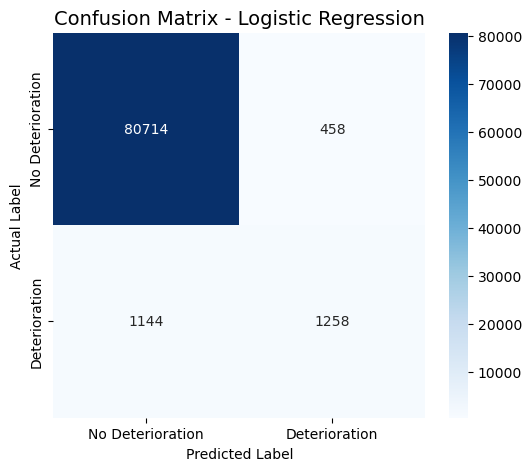

In [76]:
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Deterioration', 'Deterioration'],
    yticklabels=['No Deterioration', 'Deterioration']
)
plt.title("Confusion Matrix - Logistic Regression", fontsize=14)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.savefig("Confusion_Matrix_Logistic_Regression.png", dpi=300, bbox_inches="tight")
plt.show()

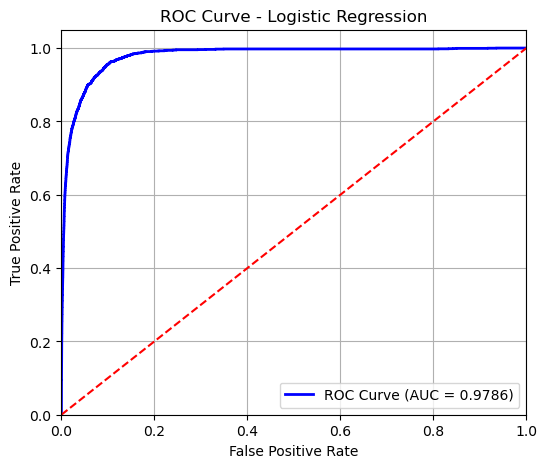

In [77]:
from sklearn.metrics import roc_curve, auc

# Predict Probabilities
y_prob = log_reg.predict_proba(X_test)[:, 1]
# Calculate ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
# Calculate AUC
roc_auc = auc(fpr, tpr)
# Plot ROC Curve
plt.figure(figsize=(6,5))
plt.plot(
    fpr,
    tpr,
    color='blue',
    linewidth=2,
    label=f'ROC Curve (AUC = {roc_auc:.4f})'
)

# Diagonal reference line
plt.plot([0,1],[0,1],'r--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig("ROC_Curve_Logistic_Regression.png", dpi=300, bbox_inches="tight")
plt.show()

In [78]:
from sklearn.ensemble import RandomForestClassifier

In [79]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [80]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [81]:
rf_pred = rf.predict(X_test)

In [82]:
rf_prob = rf.predict_proba(X_test)[:,1]

In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [84]:
rf_accuracy = accuracy_score(y_test, rf_pred)

rf_precision = precision_score(y_test, rf_pred)

rf_recall = recall_score(y_test, rf_pred)

rf_f1 = f1_score(y_test, rf_pred)

rf_auc = roc_auc_score(y_test, rf_prob)

In [85]:
rf_results = pd.DataFrame({
    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score":[
        round(rf_accuracy,4),
        round(rf_precision,4),
        round(rf_recall,4),
        round(rf_f1,4),
        round(rf_auc,4)
    ]
})

rf_results

,Metric,Score
0,Accuracy,0.9927
1,Precision,0.9575
2,Recall,0.7794
3,F1-Score,0.8593
4,ROC-AUC,0.9968


In [86]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00     81172
           1       0.96      0.78      0.86      2402

    accuracy                           0.99     83574
   macro avg       0.98      0.89      0.93     83574
weighted avg       0.99      0.99      0.99     83574



In [87]:
rf_cm = confusion_matrix(y_test, rf_pred)
print(rf_cm)

[[81089    83]
 [  530  1872]]


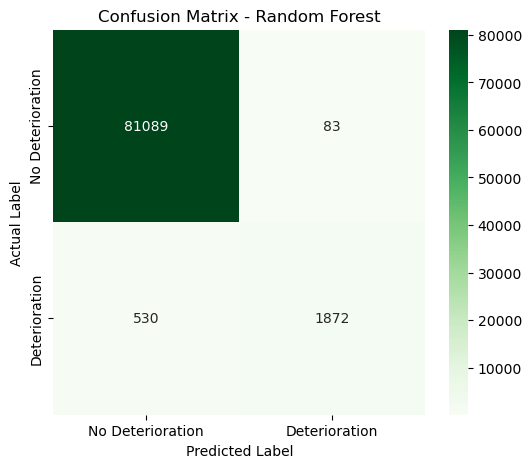

In [88]:
plt.figure(figsize=(6,5))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Deterioration','Deterioration'],
    yticklabels=['No Deterioration','Deterioration']
)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

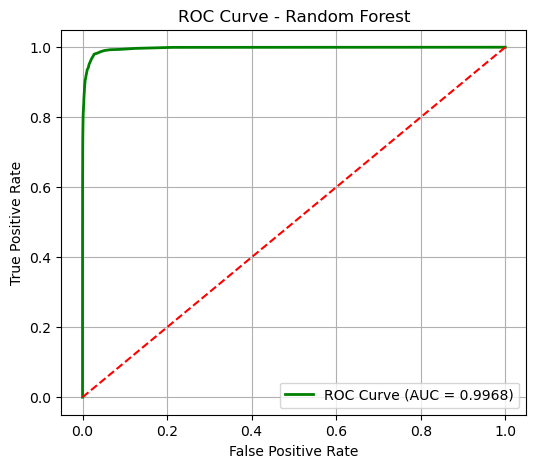

In [89]:
rf_fpr, rf_tpr, thresholds = roc_curve(y_test, rf_prob)
rf_auc = auc(rf_fpr, rf_tpr)

plt.figure(figsize=(6,5))
plt.plot(
    rf_fpr,
    rf_tpr,
    color='green',
    linewidth=2,
    label=f'ROC Curve (AUC = {rf_auc:.4f})'
)
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [90]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
feature_importance.head(10)

,Feature,Importance
0,hour_from_admission,0.221404
2,respiratory_rate,0.067664
11,lactate,0.061392
18,baseline_risk_score,0.059337
3,spo2_pct,0.052551
13,crp_level,0.051352
7,oxygen_flow,0.046820
5,systolic_bp,0.043107
1,heart_rate,0.042625
10,wbc_count,0.042387


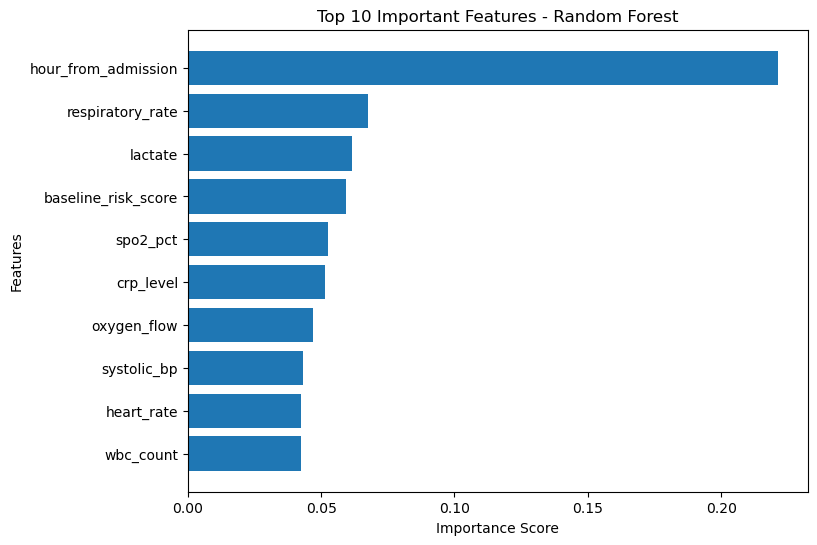

In [91]:
top10 = feature_importance.head(10)

plt.figure(figsize=(8,6))
plt.barh(
    top10["Feature"],
    top10["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")
plt.gca().invert_yaxis()
plt.show()

In [92]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [93]:
!pip install xgboost

In [94]:
from xgboost import XGBClassifier

In [95]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

In [96]:
xgb.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [97]:
xgb_pred = xgb.predict(X_test)

In [98]:
xgb_prob = xgb.predict_proba(X_test)[:,1]

In [99]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)

xgb_precision = precision_score(y_test, xgb_pred)

xgb_recall = recall_score(y_test, xgb_pred)

xgb_f1 = f1_score(y_test, xgb_pred)

xgb_auc = roc_auc_score(y_test, xgb_prob)

In [100]:
xgb_results = pd.DataFrame({
    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score":[
        round(xgb_accuracy,4),
        round(xgb_precision,4),
        round(xgb_recall,4),
        round(xgb_f1,4),
        round(xgb_auc,4)
    ]
})
xgb_results

,Metric,Score
0,Accuracy,0.9953
1,Precision,0.9573
2,Recall,0.8768
3,F1-Score,0.9153
4,ROC-AUC,0.9989


In [101]:
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     81172
           1       0.96      0.88      0.92      2402

    accuracy                           1.00     83574
   macro avg       0.98      0.94      0.96     83574
weighted avg       1.00      1.00      1.00     83574



In [102]:
xgb_cm = confusion_matrix(y_test, xgb_pred)
print(xgb_cm)

[[81078    94]
 [  296  2106]]


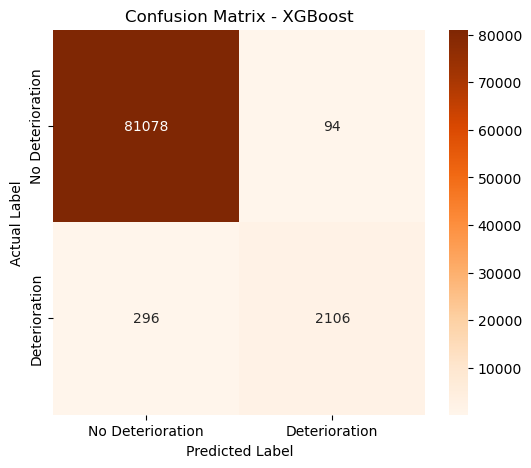

In [103]:
plt.figure(figsize=(6,5))
sns.heatmap(
    xgb_cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['No Deterioration','Deterioration'],
    yticklabels=['No Deterioration','Deterioration']
)
plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

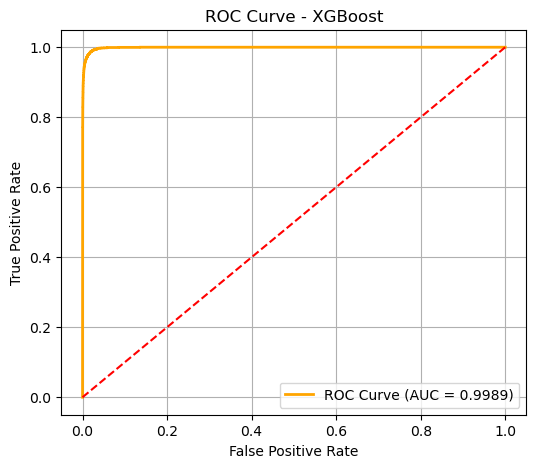

In [104]:
xgb_fpr, xgb_tpr, thresholds = roc_curve(y_test, xgb_prob)
xgb_auc = auc(xgb_fpr, xgb_tpr)
plt.figure(figsize=(6,5))
plt.plot(
    xgb_fpr,
    xgb_tpr,
    color='orange',
    linewidth=2,
    label=f'ROC Curve (AUC = {xgb_auc:.4f})'
)
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [105]:
xgb_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb.feature_importances_
})
xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)
xgb_importance.head(10)

,Feature,Importance
22,oxygen_device_niv,0.942969
0,hour_from_admission,0.012953
2,respiratory_rate,0.010276
3,spo2_pct,0.005282
13,crp_level,0.004339
8,mobility_score,0.004010
11,lactate,0.004006
17,comorbidity_index,0.002592
5,systolic_bp,0.002308
1,heart_rate,0.001505


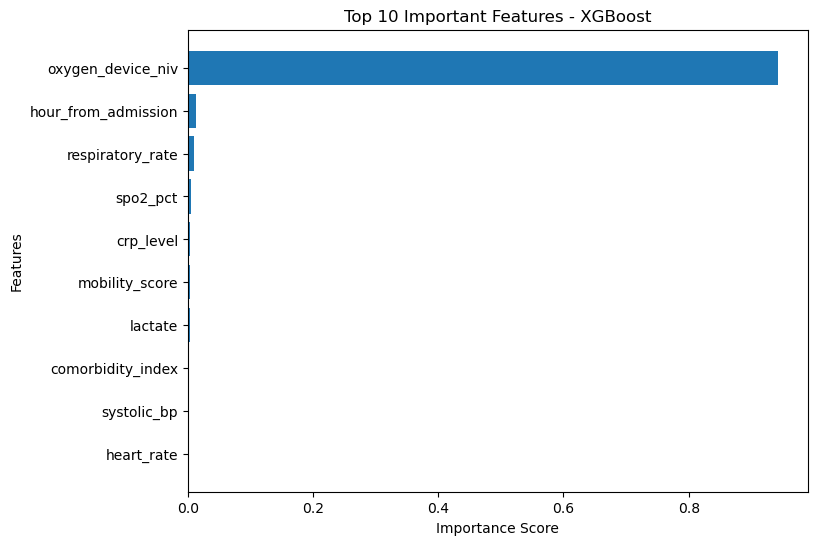

In [106]:
top10 = xgb_importance.head(10)

plt.figure(figsize=(8,6))
plt.barh(
    top10["Feature"],
    top10["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 10 Important Features - XGBoost")
plt.gca().invert_yaxis()
plt.show()

In [107]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    
    "Logistic Regression": [
        round(accuracy,4),
        round(precision,4),
        round(recall,4),
        round(f1,4),
        round(roc_auc,4)
    ],
    
    "Random Forest": [
        round(rf_accuracy,4),
        round(rf_precision,4),
        round(rf_recall,4),
        round(rf_f1,4),
        round(rf_auc,4)
    ],
    
    "XGBoost": [
        round(xgb_accuracy,4),
        round(xgb_precision,4),
        round(xgb_recall,4),
        round(xgb_f1,4),
        round(xgb_auc,4)
    ]
})
comparison

,Metric,Logistic Regression,Random Forest,XGBoost
0,Accuracy,0.9808,0.9927,0.9953
1,Precision,0.7331,0.9575,0.9573
2,Recall,0.5237,0.7794,0.8768
3,F1-Score,0.6110,0.8593,0.9153
4,ROC-AUC,0.9786,0.9968,0.9989


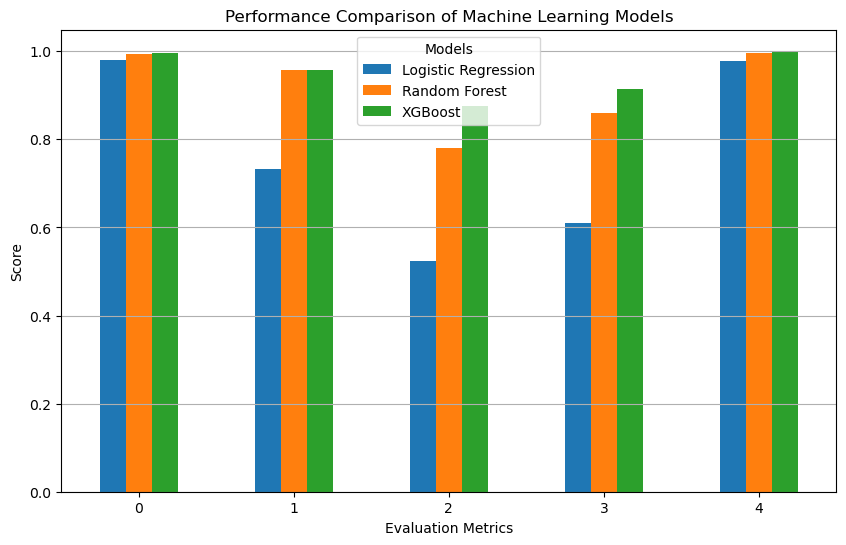

In [108]:
comparison.plot(
    kind='bar',
    figsize=(10,6)
)
plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.grid(axis='y')
plt.show()

In [111]:
best_model = comparison.set_index("Metric").loc["Accuracy"].idxmax()
print("Best Model:", best_model)

Best Model: XGBoost


In [112]:
comparison.to_csv("Model_Comparison.csv")